# Cómo están organizados los datos del proyecto (y qué tanto separan)

Este cuaderno hace con **nuestros datos de licitaciones** lo mismo que hicimos en clase con Iris:

1. Ver **dónde viven los datos** y cómo se conectan entre sí.
2. Elegir las **2 mejores características** (`SelectKBest`).
3. Dibujar la **frontera de decisión** de tres modelos (regresión logística, árbol y SVC).
4. Comprobar con honestidad si esos modelos **de verdad separan** o solo lo parece.

La pregunta de prueba: *¿se puede adivinar si una empresa llegó a ganar algún proceso solo mirando en cuántos procesos, entidades y zonas se presentó?*

> Solo lee las bases en modo lectura. No modifica nada del proyecto.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif   # elige las k características con más información sobre la clase
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.inspection import DecisionBoundaryDisplay

# La raíz del proyecto es la carpeta que contiene data/analisis.db (sirve aunque abras el cuaderno desde otra carpeta)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "analisis.db").exists())
IMG = RAIZ / "notebooks" / "img"
IMG.mkdir(parents=True, exist_ok=True)

def abrir(nombre):
    """Abre una base en solo lectura: este cuaderno nunca cambia tus datos."""
    return sqlite3.connect(f"file:{(RAIZ / 'data' / nombre).as_posix()}?mode=ro", uri=True)

analisis, licit = abrir("analisis.db"), abrir("licitaciones.db")
print("Proyecto:", RAIZ)

Proyecto: /tmp/claude-0/-home-claude/95092b62-ff32-5c01-a545-3e0d29f8a51d/scratchpad/RUN


## 1. Dónde viven los datos

Hay **dos bases**: `licitaciones.db` (lo que publica el Estado) y `analisis.db` (lo que sabemos de los competidores, con tus Excel de estudio). Cada recuadro es una tabla y el número es cuántas filas tiene **ahora**.

In [2]:
def contar(con, tabla):
    return con.execute(f"SELECT COUNT(*) FROM {tabla}").fetchone()[0]

filas = {t: contar(analisis, t) for t in ["postores", "ranking_empresas", "perfiles_empresas", "indicadores_empresas", "marcas"]}
filas |= {t: contar(licit, t) for t in ["licitaciones", "vigentes", "perucompras", "petroperu", "bnacion"]}
pd.Series(filas, name="filas").to_frame()

,filas
postores,1521
ranking_empresas,589
perfiles_empresas,31
indicadores_empresas,100
marcas,15
licitaciones,436
vigentes,2563
perucompras,1440
petroperu,523
bnacion,61


In [3]:
# ¿Qué tanto se conectan las tablas? Se cuenta cuántos valores de la llave están en las dos.
def llaves(con, tabla, col):
    return {r[0] for r in con.execute(f"SELECT DISTINCT {col} FROM {tabla} WHERE {col} IS NOT NULL")}

ruc_post, ruc_rank = llaves(analisis, "postores", "ruc"), llaves(analisis, "ranking_empresas", "ruc")
ruc_perf, ruc_ind = llaves(analisis, "perfiles_empresas", "ruc"), llaves(analisis, "indicadores_empresas", "ruc")
nom_post, nom_lic = llaves(analisis, "postores", "nomenclatura"), llaves(licit, "licitaciones", "nomenclatura")
nom_vig = llaves(licit, "vigentes", "nomenclatura")

enlaces = {
    "postores - ranking (RUC)":        f"{len(ruc_post & ruc_rank)} de {len(ruc_post)} RUC coinciden",
    "ranking - perfiles (RUC)":        f"{len(ruc_rank & ruc_perf)} de {len(ruc_rank)} empresas tienen perfil",
    "ranking - indicadores (RUC)":     f"{len(ruc_rank & ruc_ind)} de {len(ruc_rank)} empresas tienen indicadores",
    "postores - licitaciones (nomenclatura)": f"{len(nom_post & nom_lic)} de {len(nom_post)} procesos coinciden",
    "licitaciones - vigentes (nomenclatura)": f"{len(nom_lic & nom_vig)} coinciden (es lo normal: vigentes aún no están en el histórico)",
}
pd.Series(enlaces, name="qué tanto se conectan").to_frame()

,qué tanto se conectan
postores - ranking (RUC),589 de 589 RUC coinciden
ranking - perfiles (RUC),31 de 589 empresas tienen perfil
ranking - indicadores (RUC),100 de 589 empresas tienen indicadores
postores - licitaciones (nomenclatura),53 de 83 procesos coinciden
licitaciones - vigentes (nomenclatura),2 coinciden (es lo normal: vigentes aún no est...


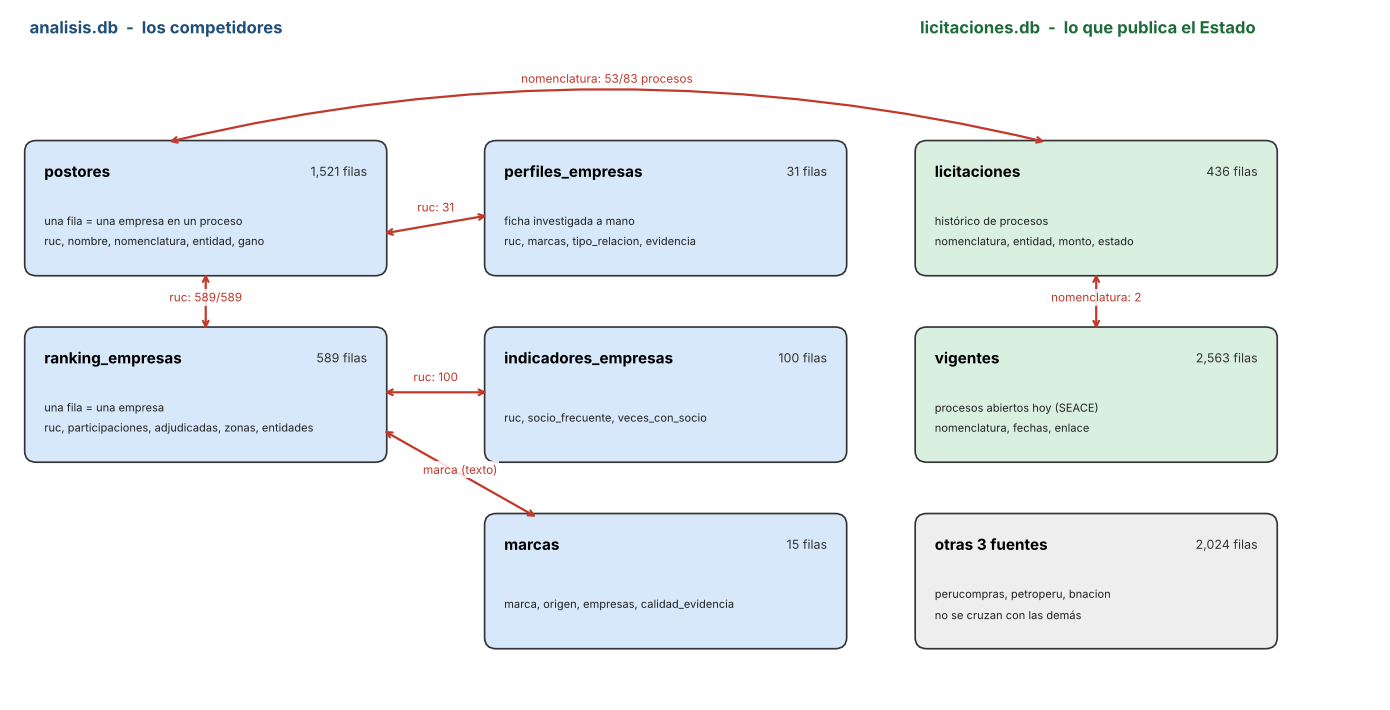

In [4]:
# Diagrama: una caja por tabla, una flecha por cada llave que las une.
def caja(ax, x, y, titulo, n, cols, color, ancho=3.6, alto=1.35):
    ax.add_patch(FancyBboxPatch((x, y), ancho, alto, boxstyle="round,pad=0.05,rounding_size=0.12",
                                fc=color, ec="#333", lw=1.2))
    ax.text(x + 0.15, y + alto - 0.28, titulo, fontsize=11, fontweight="bold", va="center")
    ax.text(x + ancho - 0.15, y + alto - 0.28, f"{n:,} filas", fontsize=9, ha="right", va="center", color="#333")
    ax.text(x + 0.15, y + 0.42, cols, fontsize=8, va="center", color="#222", linespacing=1.5)

def flecha(ax, p, q, texto, dy=0.12):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="<->", lw=1.6, color="#c0392b"))
    ax.text((p[0] + q[0]) / 2, (p[1] + q[1]) / 2 + dy, texto, fontsize=8.5, ha="center", color="#c0392b",
            bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))

fig, ax = plt.subplots(figsize=(14, 7.2))
ax.set_xlim(0, 14); ax.set_ylim(0, 7.4); ax.axis("off")
AZUL, VERDE, GRIS = "#d6e8fa", "#d9f0e1", "#eeeeee"

ax.text(0.2, 7.15, "analisis.db  -  los competidores", fontsize=12, fontweight="bold", color="#1f4e79")
ax.text(9.3, 7.15, "licitaciones.db  -  lo que publica el Estado", fontsize=12, fontweight="bold", color="#1e6b3a")

caja(ax, 0.2, 4.6, "postores", filas["postores"], "una fila = una empresa en un proceso\nruc, nombre, nomenclatura, entidad, gano", AZUL)
caja(ax, 0.2, 2.6, "ranking_empresas", filas["ranking_empresas"], "una fila = una empresa\nruc, participaciones, adjudicadas, zonas, entidades", AZUL)
caja(ax, 4.9, 4.6, "perfiles_empresas", filas["perfiles_empresas"], "ficha investigada a mano\nruc, marcas, tipo_relacion, evidencia", AZUL)
caja(ax, 4.9, 2.6, "indicadores_empresas", filas["indicadores_empresas"], "ruc, socio_frecuente, veces_con_socio", AZUL)
caja(ax, 4.9, 0.6, "marcas", filas["marcas"], "marca, origen, empresas, calidad_evidencia", AZUL)
caja(ax, 9.3, 4.6, "licitaciones", filas["licitaciones"], "histórico de procesos\nnomenclatura, entidad, monto, estado", VERDE)
caja(ax, 9.3, 2.6, "vigentes", filas["vigentes"], "procesos abiertos hoy (SEACE)\nnomenclatura, fechas, enlace", VERDE)
caja(ax, 9.3, 0.6, "otras 3 fuentes", filas["perucompras"] + filas["petroperu"] + filas["bnacion"],
     "perucompras, petroperu, bnacion\nno se cruzan con las demás", GRIS)

flecha(ax, (2.0, 4.6), (2.0, 3.95), f"ruc: {len(ruc_post & ruc_rank)}/{len(ruc_post)}", dy=0)
flecha(ax, (3.8, 3.3), (4.9, 3.3), f"ruc: {len(ruc_rank & ruc_ind)}", dy=0.12)
flecha(ax, (3.8, 5.0), (4.9, 5.2), f"ruc: {len(ruc_rank & ruc_perf)}", dy=0.14)
flecha(ax, (3.8, 2.9), (5.4, 1.95), "marca (texto)", dy=0.0)
ax.annotate("", xy=(10.6, 5.98), xytext=(1.6, 5.98), arrowprops=dict(arrowstyle="<->", lw=1.6, color="#c0392b", connectionstyle="arc3,rad=-0.12"))
ax.text(6.1, 6.62, f"nomenclatura: {len(nom_post & nom_lic)}/{len(nom_post)} procesos", fontsize=8.5, ha="center", color="#c0392b",
        bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
flecha(ax, (11.1, 4.6), (11.1, 3.95), f"nomenclatura: {len(nom_lic & nom_vig)}", dy=0)
plt.tight_layout()
plt.savefig(IMG / "mapa_datos.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. La pregunta de prueba

Cada fila de `ranking_empresas` es una empresa. Queremos adivinar si **ganó al menos un proceso** (`adjudicadas > 0`) usando solo *dónde y cuánto se presentó*.

**Cuidado con la trampa:** se dejan fuera `adjudicadas`, `tasa_adjudicacion` y `puntaje`, porque ya contienen la respuesta (un modelo que las use "acierta" sin aprender nada). Esto se llama *fuga de información*.

In [5]:
empresas = pd.read_sql("SELECT * FROM ranking_empresas", analisis)

CARACTERISTICAS = ["participaciones", "anios_activos", "procesos_2026", "procesos_sur", "zonas", "entidades"]
x = empresas[CARACTERISTICAS]
y = (empresas["adjudicadas"] > 0).astype(int)      # 1 = ganó alguna vez, 0 = nunca ganó

print(f"{len(empresas)} empresas: {y.sum()} ganaron alguna vez ({y.mean():.0%}) y {(y == 0).sum()} nunca ganaron")
x.describe().loc[["min", "50%", "max"]].T

589 empresas: 64 ganaron alguna vez (11%) y 525 nunca ganaron


,min,50%,max
participaciones,1.0,1.0,38.0
anios_activos,1.0,1.0,4.0
procesos_2026,0.0,0.0,9.0
procesos_sur,0.0,1.0,22.0
zonas,1.0,1.0,19.0
entidades,1.0,1.0,25.0


Fíjate en la mediana (`50%`): la mayoría de empresas se presentó **una sola vez**, y unas pocas llegan a 38. Por eso más abajo se usa el logaritmo, que acerca los extremos.

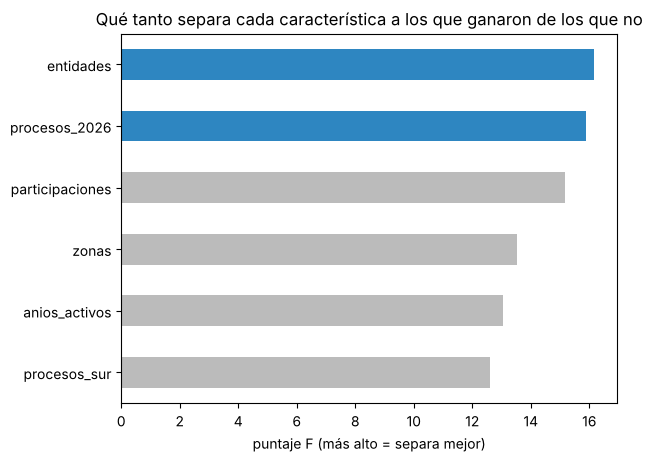

Las 2 mejores características: ['procesos_2026', 'entidades']


In [6]:
# Las 2 mejores características, igual que en clase
selector = SelectKBest(k=2, score_func=f_classif)
selector.fit(x, y)

puntajes = pd.Series(selector.scores_, index=CARACTERISTICAS).sort_values()
puntajes.plot.barh(color=["#2e86c1" if c in puntajes.index[-2:] else "#bbb" for c in puntajes.index])
plt.title("Qué tanto separa cada característica a los que ganaron de los que no")
plt.xlabel("puntaje F (más alto = separa mejor)")
plt.show()

indices = selector.get_support(indices=True)
mejores = [CARACTERISTICAS[i] for i in indices]
print("Las 2 mejores características:", mejores)

In [7]:
# Con las 2 mejores: log1p acerca los extremos (1 vs 38), luego separamos entrenamiento y prueba
x2 = np.log1p(empresas[mejores].values)
x_train, x_test, y_train, y_test = train_test_split(x2, y, test_size=0.2, random_state=42, stratify=y)

# class_weight="balanced": como hay pocos ganadores, cada uno pesa más para que el modelo no los ignore
modelos = {
    "Regresión logística": LogisticRegression(class_weight="balanced"),
    "Árbol de decisión":   DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42),
    "SVC":                 SVC(kernel="rbf", class_weight="balanced"),
}
entrenados = {}
for nombre, clasificador in modelos.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("classifier", clasificador)])
    pipe.fit(x_train, y_train)
    entrenados[nombre] = pipe
    print(f"{nombre:20s} accuracy en prueba: {pipe.score(x_test, y_test):.2f}")

Regresión logística  accuracy en prueba: 0.72
Árbol de decisión    accuracy en prueba: 0.83
SVC                  accuracy en prueba: 0.82


## 3. Frontera de decisión

Igual que en clase: cada zona de color es lo que predice el modelo y los puntos son las empresas de prueba (**rojo = ganó alguna vez**, azul = nunca ganó). Un punto sobre la zona de su color es un acierto.

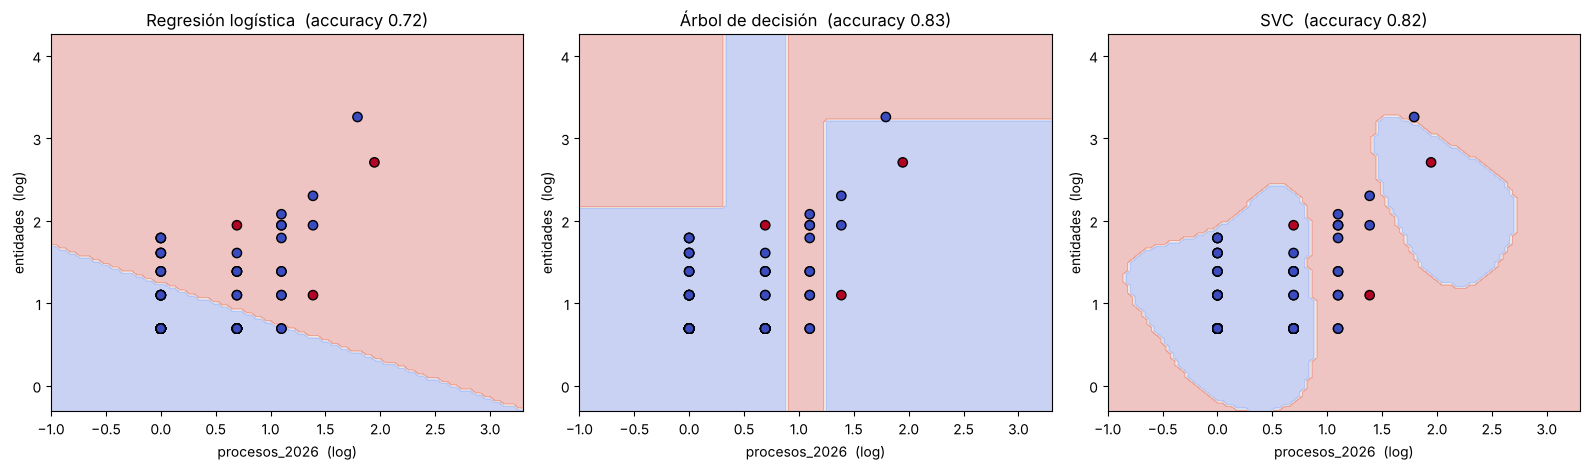

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nombre, pipe) in zip(ejes, entrenados.items()):
    DecisionBoundaryDisplay.from_estimator(pipe, x_train, response_method="predict", alpha=0.3, cmap="coolwarm", ax=ax)
    ax.scatter(x_test[:, 0], x_test[:, 1], c=y_test, edgecolor="k", cmap="coolwarm", s=45)
    ax.set_title(f"{nombre}  (accuracy {pipe.score(x_test, y_test):.2f})")
    ax.set_xlabel(f"{mejores[0]}  (log)")
    ax.set_ylabel(f"{mejores[1]}  (log)")
plt.tight_layout()
plt.savefig(IMG / "fronteras.png", dpi=110, bbox_inches="tight")
plt.show()

## 4. ¿Separan de verdad? El accuracy engaña

Si solo el 11 % de las empresas ganó, un "modelo" que responda **siempre "nunca ganó"** ya acierta casi el 89 %. Por eso se compara contra ese modelo tonto (`DummyClassifier`) y se usa la **exactitud balanceada** (promedia el acierto en ganadores y en no ganadores; el azar da 0.5). Para que no dependa de una sola partición, se repite 5 × 3 veces.

In [9]:
validacion = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
candidatos = {"Siempre «no ganó» (modelo tonto)": DummyClassifier(strategy="most_frequent"), **modelos}

resultados = []
for nombre, clasificador in candidatos.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("classifier", clasificador)])
    acc = cross_val_score(pipe, x2, y, cv=validacion, scoring="accuracy")
    bal = cross_val_score(pipe, x2, y, cv=validacion, scoring="balanced_accuracy")
    resultados.append({"modelo": nombre, "accuracy": acc.mean(), "exactitud balanceada": bal.mean(), "variación (±)": bal.std()})

tabla = pd.DataFrame(resultados).set_index("modelo").round(2)
tabla

,accuracy,exactitud balanceada,variación (±)
modelo,,,
Siempre «no ganó» (modelo tonto),0.89,0.50,0.00
Regresión logística,0.65,0.56,0.05
Árbol de decisión,0.83,0.59,0.05
SVC,0.81,0.58,0.05


In [10]:
# La regla decide el veredicto (no la opinión). Se mira el peor caso razonable (media - variación):
#   >= 0.60 señal clara | > 0.50 señal débil | si no, no concluyente. El azar da 0.50.
veredictos = []
for nombre, fila in tabla.iloc[1:].iterrows():
    peor = fila["exactitud balanceada"] - fila["variación (±)"]
    v = "señal clara" if peor >= 0.60 else "señal débil" if peor > 0.50 else "no concluyente"
    veredictos.append(v)
    print(f"{nombre:20s} -> {v} (balanceada {fila['exactitud balanceada']:.2f} ± {fila['variación (±)']:.2f})")

print()
if "señal clara" in veredictos:
    print("Con estas 2 características se separa a los ganadores claramente mejor que al azar.")
elif "señal débil" in veredictos:
    print("Hay una señal débil: mejora un poco al azar, pero no alcanza para decidir por sí sola.")
    print("Sirve para ordenar o priorizar empresas, no para afirmar quién ganará.")
else:
    print("Con estas 2 características no se distingue a quien gana de quien no mejor que el azar.")

Regresión logística  -> señal débil (balanceada 0.56 ± 0.05)
Árbol de decisión    -> señal débil (balanceada 0.59 ± 0.05)
SVC                  -> señal débil (balanceada 0.58 ± 0.05)

Hay una señal débil: mejora un poco al azar, pero no alcanza para decidir por sí sola.
Sirve para ordenar o priorizar empresas, no para afirmar quién ganará.


## 5. Qué nos deja

- El **mapa de datos** muestra qué tablas se conectan por RUC o por nomenclatura, y cuáles no (las otras fuentes están solas).
- La **frontera de decisión** permite *ver* cómo cada modelo parte el espacio: la logística con una línea, el árbol con rectángulos y el SVC con zonas curvas.
- La **validación** dice si esa separación es real. Lo que mande la celda anterior es el resultado; este texto no lo cambia.
- Es la misma idea del proyecto: **las reglas y la validación deciden, el modelo solo estima**, y cuando la evidencia es débil se responde *"no concluyente"* (ver `src/ml/predictor.py` y `src/ml/validar.py`).